# ToolCallLimitedMiddleware中间件
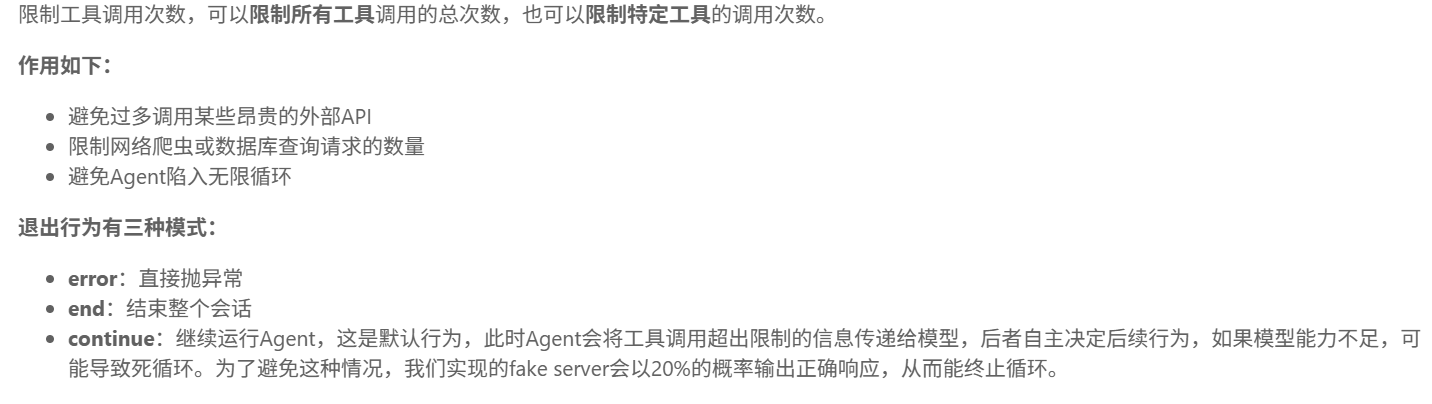

## 1.限制整个会话，优雅退出
### 还是需要那个fake_deep_seekserver


In [2]:
from pydantic import BaseModel, Field
from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, PIIMiddleware, TodoListMiddleware, \
    ToolCallLimitMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from langchain.agents.middleware import ModelCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver


# 1.初始化模型给中间件使用，不是agent
model = ChatOpenAI(
    model="any", # 这个模型必须和fake_deepseek_server返回的模型名称一致
    api_key="sk12345",
    base_url="http://127.0.0.1:8889", # 必须是fake_deepseek_server提供的url
)

# 定义输出格式的结构
class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱地址")
    phone: str = Field(description="用户的手机号")


class EventInfo(BaseModel):
    event_name: str = Field(description="事件名称")
    date: str = Field(description="事件发生日期")

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    middleware=[
        ToolCallLimitMiddleware(
            thread_limit=2,
            run_limit=2,
            exit_behavior='end'
        ),
    ],
    response_format=Union[ContactInfo,EventInfo],
)

config = {"configurable":{"thread_id":"1"}}

resp = agent.invoke({"messages":[
   HumanMessage(content="你好")
]},config=config)

for msg in resp["messages"]:
    msg.pretty_print()


================================ Human Message =================================

你好
================================== Ai Message ==================================
Tool Calls:
  ContactInfo (call_1)
 Call ID: call_1
  Args:
    name: 康师傅
    email: songhongkang@atguigu.cn
    phone: 12345678912
  EventInfo (call_2)
 Call ID: call_2
  Args:
    event_name: 问数项目启动会
    date: 2026-03-27
================================= Tool Message =================================
Name: ContactInfo

Error: Model incorrectly returned multiple structured responses (ContactInfo, EventInfo) when only one is expected.
 Please fix your mistakes.
================================= Tool Message =================================
Name: EventInfo

Error: Model incorrectly returned multiple structured responses (ContactInfo, EventInfo) when only one is expected.
 Please fix your mistakes.
================================== Ai Message ==================================
Tool Calls:
  ContactInfo (call_1)
 Call ID: c